<a href="https://colab.research.google.com/github/pritamsahu330/CCA-3-Computer-Vision/blob/main/cv_tasks.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
import os

from skimage.metrics import peak_signal_noise_ratio as psnr
from skimage.metrics import structural_similarity as ssim

print("All libraries imported successfully!")
print("OpenCV:", cv2.__version__)
print("NumPy:", np.__version__)

All libraries imported successfully!
OpenCV: 5.0.0
NumPy: 2.3.5


In [ ]:
os.makedirs("data", exist_ok=True)
os.makedirs("outputs", exist_ok=True)

print("Project directories ready!")

Project directories ready!


In [ ]:
# Load photographs

photo1 = cv2.imread("data/photo1.jpeg")
photo2 = cv2.imread("data/photo2.jpeg")

# Verify images

if photo1 is None or photo2 is None:
    print("Error loading photographs. Check file paths.")
else:
    print("Both photographs loaded successfully!")

Both photographs loaded successfully!


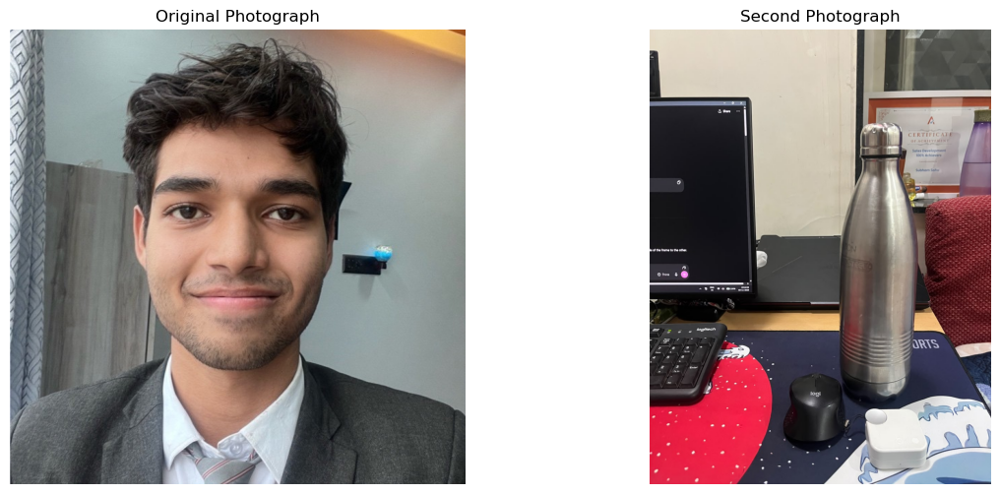

In [ ]:
# Convert BGR to RGB

photo1_rgb = cv2.cvtColor(photo1, cv2.COLOR_BGR2RGB)
photo2_rgb = cv2.cvtColor(photo2, cv2.COLOR_BGR2RGB)

# Display images

plt.figure(figsize=(14, 6))

plt.subplot(1, 2, 1)
plt.imshow(photo1_rgb)
plt.title("Original Photograph")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(photo2_rgb)
plt.title("Second Photograph")
plt.axis("off")

plt.show()

In [ ]:
print("Photo 1 Dimensions:", photo1.shape)
print("Photo 2 Dimensions:", photo2.shape)

Photo 1 Dimensions: (675, 675, 3)
Photo 2 Dimensions: (1280, 960, 3)


In [ ]:
import os

os.makedirs("outputs", exist_ok=True)

print("Output folder is ready!")

Output folder is ready!


In [ ]:
# Convert image into floating-point format
image = photo1.astype(np.float32)

# Set noise parameters
mean = 0
sigma = 25

# Generate Gaussian noise
gaussian_noise = np.random.normal(
    mean,
    sigma,
    image.shape
)

# Add noise to original image
noisy_image = image + gaussian_noise

# Keep pixel values between 0 and 255
noisy_image = np.clip(noisy_image, 0, 255)

# Convert back to uint8
noisy_image = noisy_image.astype(np.uint8)

print("Gaussian noise added successfully!")

Gaussian noise added successfully!


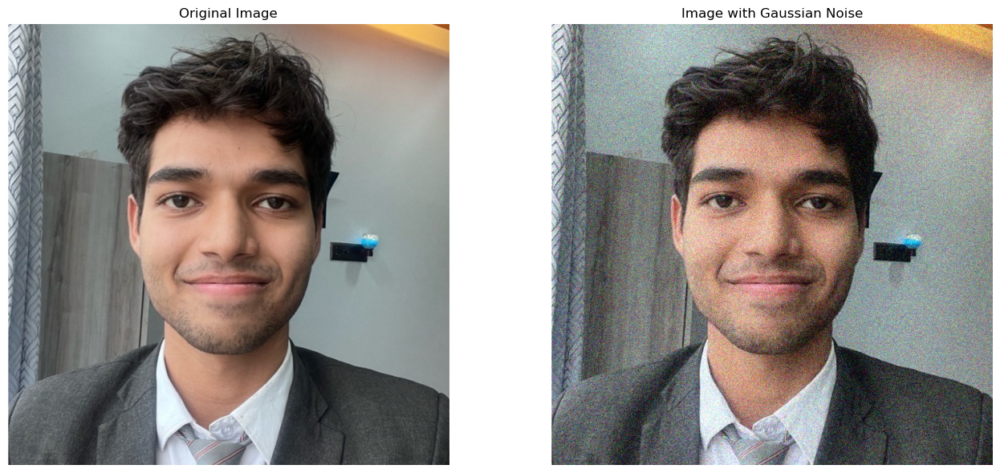

In [ ]:
# Convert images from BGR to RGB for display

original_rgb = cv2.cvtColor(photo1, cv2.COLOR_BGR2RGB)

noisy_rgb = cv2.cvtColor(
    noisy_image,
    cv2.COLOR_BGR2RGB
)

# Display comparison

plt.figure(figsize=(14, 6))

plt.subplot(1, 2, 1)
plt.imshow(original_rgb)
plt.title("Original Image")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(noisy_rgb)
plt.title("Image with Gaussian Noise")
plt.axis("off")

plt.tight_layout()
plt.show()

In [ ]:
cv2.imwrite(
    "outputs/gaussian_noise.jpg",
    noisy_image
)

print("Gaussian noisy image saved successfully!")

Gaussian noisy image saved successfully!


In [ ]:
# Copy the original image
sp_image = photo1.copy()

# Set noise percentage
noise_percentage = 0.05

# Calculate total number of pixels
total_pixels = photo1.shape[0] * photo1.shape[1]

# Calculate number of noisy pixels
num_noise = int(noise_percentage * total_pixels)

# Generate random coordinates
rows = np.random.randint(0, photo1.shape[0], num_noise)
cols = np.random.randint(0, photo1.shape[1], num_noise)

# Half the selected pixels become white (Salt)
sp_image[rows[:num_noise//2], cols[:num_noise//2]] = 255

# Remaining selected pixels become black (Pepper)
sp_image[rows[num_noise//2:], cols[num_noise//2:]] = 0

print("Salt-and-Pepper noise added successfully!")

Salt-and-Pepper noise added successfully!


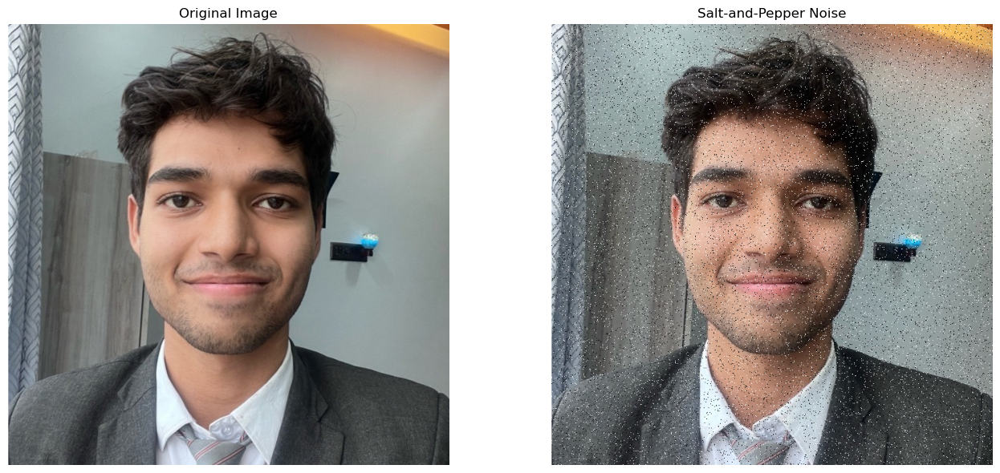

In [ ]:
# Convert BGR to RGB

original_rgb = cv2.cvtColor(photo1, cv2.COLOR_BGR2RGB)

sp_rgb = cv2.cvtColor(sp_image, cv2.COLOR_BGR2RGB)

# Display comparison

plt.figure(figsize=(14, 6))

plt.subplot(1, 2, 1)
plt.imshow(original_rgb)
plt.title("Original Image")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(sp_rgb)
plt.title("Salt-and-Pepper Noise")
plt.axis("off")

plt.tight_layout()
plt.show()

In [ ]:
cv2.imwrite(
    "outputs/salt_pepper_noise.jpg",
    sp_image
)

print("Salt-and-Pepper image saved successfully!")

Salt-and-Pepper image saved successfully!


In [ ]:
# Apply Gaussian Blur to Gaussian noisy image

gaussian_filtered = cv2.GaussianBlur(
    noisy_image,
    (5, 5),
    0
)

print("Gaussian filtering completed!")

Gaussian filtering completed!


In [ ]:
# Apply Median Filter to Salt-and-Pepper noisy image

median_filtered = cv2.medianBlur(
    sp_image,
    5
)

print("Median filtering completed!")

Median filtering completed!


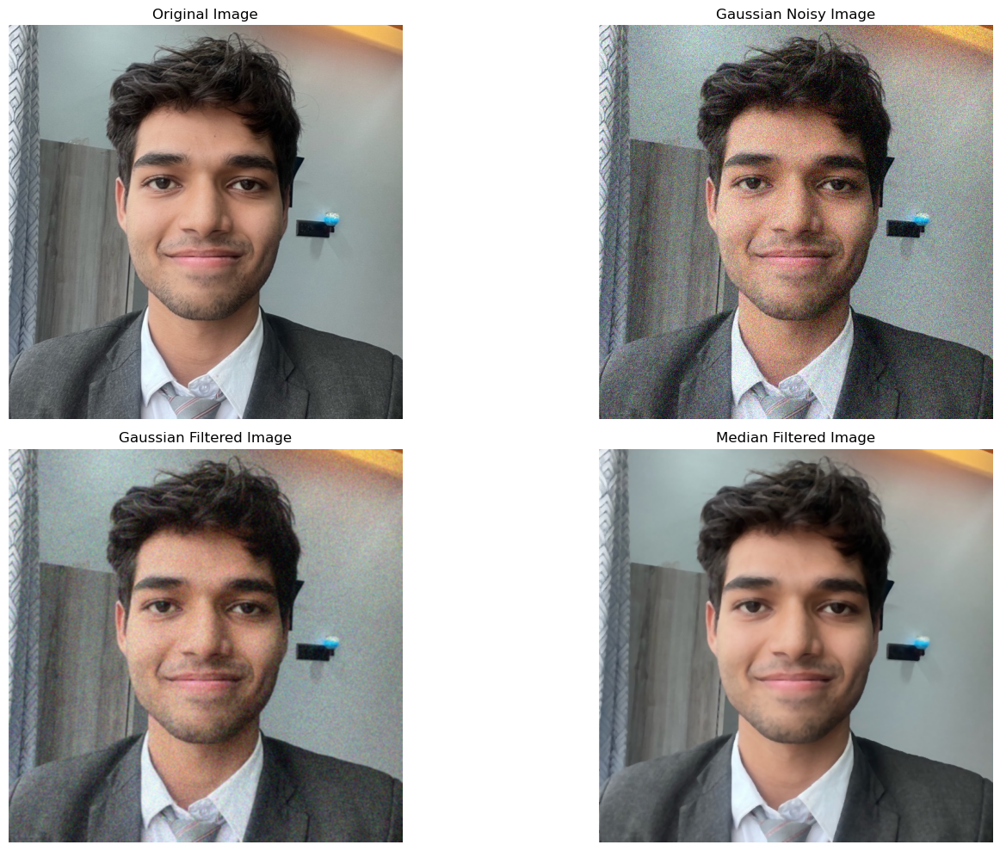

In [ ]:
# Convert images from BGR to RGB

original = cv2.cvtColor(photo1, cv2.COLOR_BGR2RGB)

gaussian_noisy = cv2.cvtColor(
    noisy_image, cv2.COLOR_BGR2RGB
)

gaussian_restored = cv2.cvtColor(
    gaussian_filtered, cv2.COLOR_BGR2RGB
)

sp_noisy = cv2.cvtColor(
    sp_image, cv2.COLOR_BGR2RGB
)

median_restored = cv2.cvtColor(
    median_filtered, cv2.COLOR_BGR2RGB
)

# Display results

plt.figure(figsize=(16, 10))

plt.subplot(2, 2, 1)
plt.imshow(original)
plt.title("Original Image")
plt.axis("off")

plt.subplot(2, 2, 2)
plt.imshow(gaussian_noisy)
plt.title("Gaussian Noisy Image")
plt.axis("off")

plt.subplot(2, 2, 3)
plt.imshow(gaussian_restored)
plt.title("Gaussian Filtered Image")
plt.axis("off")

plt.subplot(2, 2, 4)
plt.imshow(median_restored)
plt.title("Median Filtered Image")
plt.axis("off")

plt.tight_layout()
plt.show()

In [ ]:
cv2.imwrite(
    "outputs/gaussian_filtered.jpg",
    gaussian_filtered
)

cv2.imwrite(
    "outputs/median_filtered.jpg",
    median_filtered
)

print("Both restored images saved successfully!")

Both restored images saved successfully!


In [ ]:
# Convert all images from BGR to RGB

original_rgb = cv2.cvtColor(photo1, cv2.COLOR_BGR2RGB)

gaussian_noisy_rgb = cv2.cvtColor(
    noisy_image, cv2.COLOR_BGR2RGB
)

gaussian_restored_rgb = cv2.cvtColor(
    gaussian_filtered, cv2.COLOR_BGR2RGB
)

sp_noisy_rgb = cv2.cvtColor(
    sp_image, cv2.COLOR_BGR2RGB
)

median_restored_rgb = cv2.cvtColor(
    median_filtered, cv2.COLOR_BGR2RGB
)

print("All images prepared for comparison!")

All images prepared for comparison!


In [ ]:
# Calculate PSNR values

psnr_gaussian_noisy = psnr(
    original_rgb,
    gaussian_noisy_rgb,
    data_range=255
)

psnr_gaussian_restored = psnr(
    original_rgb,
    gaussian_restored_rgb,
    data_range=255
)

psnr_sp_noisy = psnr(
    original_rgb,
    sp_noisy_rgb,
    data_range=255
)

psnr_median_restored = psnr(
    original_rgb,
    median_restored_rgb,
    data_range=255
)

print("PSNR RESULTS")

print("Gaussian Noisy Image:", round(psnr_gaussian_noisy, 2), "dB")
print("Gaussian Restored Image:", round(psnr_gaussian_restored, 2), "dB")

print("Salt-Pepper Noisy Image:", round(psnr_sp_noisy, 2), "dB")
print("Median Restored Image:", round(psnr_median_restored, 2), "dB")

PSNR RESULTS
Gaussian Noisy Image: 20.34 dB
Gaussian Restored Image: 29.61 dB
Salt-Pepper Noisy Image: 18.45 dB
Median Restored Image: 32.72 dB


In [ ]:
# Calculate SSIM values

ssim_gaussian_noisy = ssim(
    original_rgb,
    gaussian_noisy_rgb,
    channel_axis=-1,
    data_range=255
)

ssim_gaussian_restored = ssim(
    original_rgb,
    gaussian_restored_rgb,
    channel_axis=-1,
    data_range=255
)

ssim_sp_noisy = ssim(
    original_rgb,
    sp_noisy_rgb,
    channel_axis=-1,
    data_range=255
)

ssim_median_restored = ssim(
    original_rgb,
    median_restored_rgb,
    channel_axis=-1,
    data_range=255
)

print("SSIM RESULTS")

print("Gaussian Noisy Image:", round(ssim_gaussian_noisy, 4))
print("Gaussian Restored Image:", round(ssim_gaussian_restored, 4))

print("Salt-Pepper Noisy Image:", round(ssim_sp_noisy, 4))
print("Median Restored Image:", round(ssim_median_restored, 4))

SSIM RESULTS
Gaussian Noisy Image: 0.2366
Gaussian Restored Image: 0.6878
Salt-Pepper Noisy Image: 0.2985
Median Restored Image: 0.8753


In [ ]:
import pandas as pd

results = {
    "Image": [
        "Gaussian Noisy",
        "Gaussian Restored",
        "Salt-Pepper Noisy",
        "Median Restored"
    ],

    "PSNR (dB)": [
        psnr_gaussian_noisy,
        psnr_gaussian_restored,
        psnr_sp_noisy,
        psnr_median_restored
    ],

    "SSIM": [
        ssim_gaussian_noisy,
        ssim_gaussian_restored,
        ssim_sp_noisy,
        ssim_median_restored
    ]
}

comparison_df = pd.DataFrame(results)

comparison_df = comparison_df.round(4)

display(comparison_df)

,Image,PSNR (dB),SSIM
0,Gaussian Noisy,20.3448,0.2366
1,Gaussian Restored,29.6131,0.6878
2,Salt-Pepper Noisy,18.4472,0.2985
3,Median Restored,32.7169,0.8753


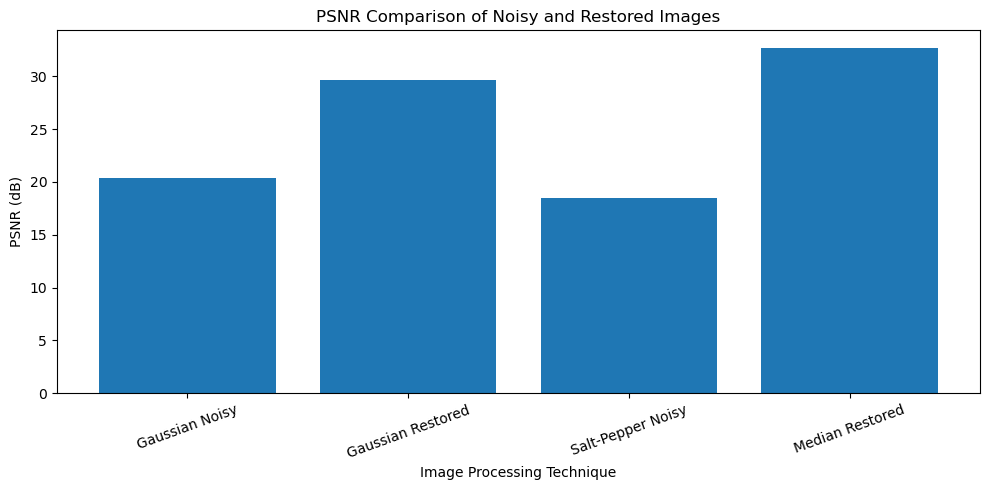

In [ ]:
plt.figure(figsize=(10, 5))

plt.bar(
    comparison_df["Image"],
    comparison_df["PSNR (dB)"]
)

plt.title("PSNR Comparison of Noisy and Restored Images")
plt.xlabel("Image Processing Technique")
plt.ylabel("PSNR (dB)")

plt.xticks(rotation=20)
plt.tight_layout()
plt.show()

In [ ]:
comparison_df.to_csv(
    "outputs/image_quality_comparison.csv",
    index=False
)

print("Comparison results saved successfully!")

Comparison results saved successfully!


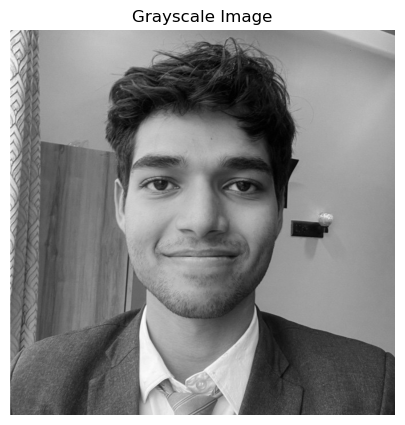

In [ ]:
# Convert original photograph to grayscale

gray_image = cv2.cvtColor(
    photo1,
    cv2.COLOR_BGR2GRAY
)

plt.figure(figsize=(8,5))

plt.imshow(gray_image, cmap="gray")
plt.title("Grayscale Image")
plt.axis("off")

plt.show()

Thresholding completed!
Threshold value: 127.0


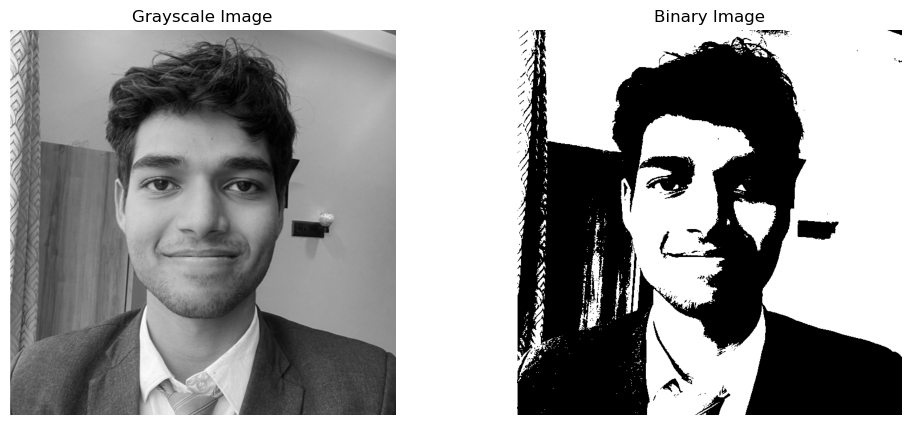

In [ ]:
# Apply binary thresholding

threshold_value = 127

ret, binary_image = cv2.threshold(
    gray_image,
    threshold_value,
    255,
    cv2.THRESH_BINARY
)

print("Thresholding completed!")
print("Threshold value:", ret)

plt.figure(figsize=(12,5))

plt.subplot(1,2,1)
plt.imshow(gray_image, cmap="gray")
plt.title("Grayscale Image")
plt.axis("off")

plt.subplot(1,2,2)
plt.imshow(binary_image, cmap="gray")
plt.title("Binary Image")
plt.axis("off")

plt.show()

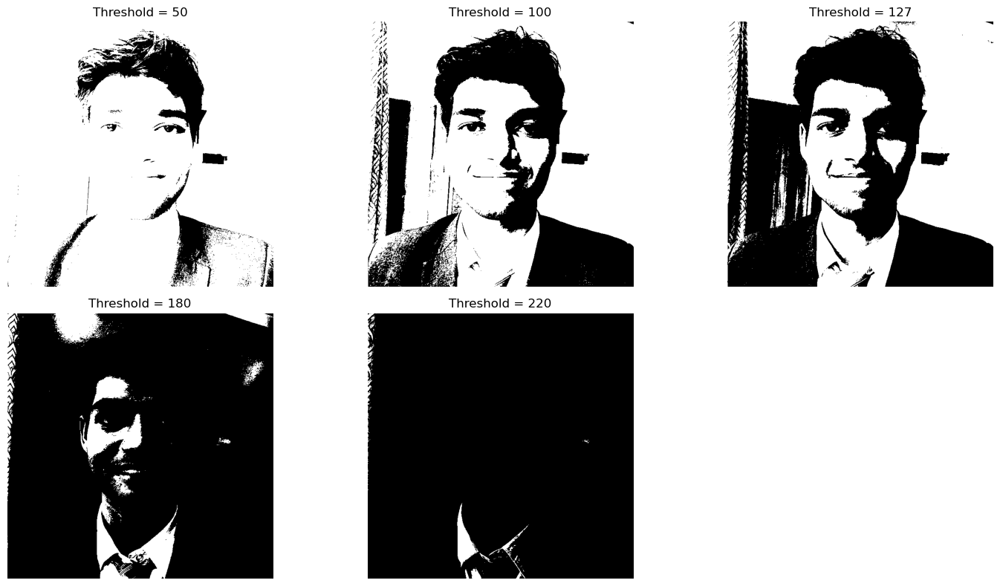

In [ ]:
thresholds = [50, 100, 127, 180, 220]

plt.figure(figsize=(15,8))

for i, value in enumerate(thresholds):

    _, result = cv2.threshold(
        gray_image,
        value,
        255,
        cv2.THRESH_BINARY
    )

    plt.subplot(2,3,i+1)
    plt.imshow(result, cmap="gray")
    plt.title(f"Threshold = {value}")
    plt.axis("off")

plt.tight_layout()
plt.show()

In [ ]:
cv2.imwrite(
    "outputs/binary_threshold.png",
    binary_image
)

print("Binary image saved successfully!")

Binary image saved successfully!


In [ ]:
# Create a 5x5 kernel
kernel = np.ones((5, 5), np.uint8)

print("Structuring Element:")
print(kernel)

Structuring Element:
[[1 1 1 1 1]
 [1 1 1 1 1]
 [1 1 1 1 1]
 [1 1 1 1 1]
 [1 1 1 1 1]]


In [ ]:
# 1. Erosion
erosion = cv2.erode(binary_image, kernel, iterations=1)

# 2. Dilation
dilation = cv2.dilate(binary_image, kernel, iterations=1)

# 3. Opening
opening = cv2.morphologyEx(binary_image, cv2.MORPH_OPEN, kernel)

# 4. Closing
closing = cv2.morphologyEx(binary_image, cv2.MORPH_CLOSE, kernel)

print("All morphological operations completed successfully.")

All morphological operations completed successfully.


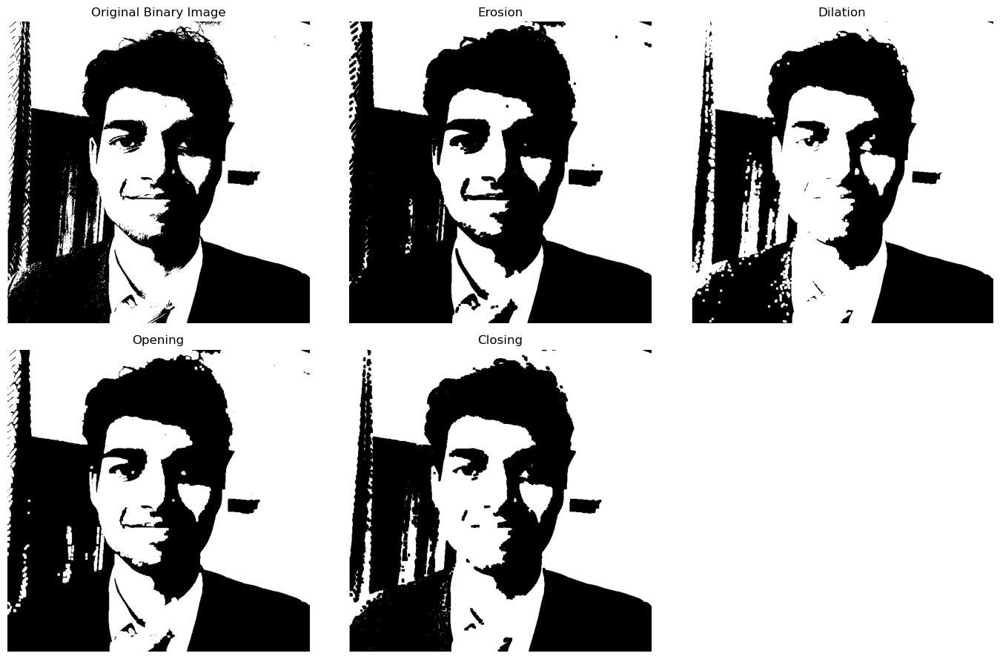

In [ ]:
plt.figure(figsize=(14, 9))

plt.subplot(2, 3, 1)
plt.imshow(binary_image, cmap='gray')
plt.title("Original Binary Image")
plt.axis("off")

plt.subplot(2, 3, 2)
plt.imshow(erosion, cmap='gray')
plt.title("Erosion")
plt.axis("off")

plt.subplot(2, 3, 3)
plt.imshow(dilation, cmap='gray')
plt.title("Dilation")
plt.axis("off")

plt.subplot(2, 3, 4)
plt.imshow(opening, cmap='gray')
plt.title("Opening")
plt.axis("off")

plt.subplot(2, 3, 5)
plt.imshow(closing, cmap='gray')
plt.title("Closing")
plt.axis("off")

plt.tight_layout()
plt.show()

In [ ]:
cv2.imwrite("outputs/erosion.png", erosion)
cv2.imwrite("outputs/dilation.png", dilation)
cv2.imwrite("outputs/opening.png", opening)
cv2.imwrite("outputs/closing.png", closing)

print("All output images saved successfully.")

All output images saved successfully.


In [ ]:
# Convert the original image into grayscale
gray_image = cv2.cvtColor(photo1, cv2.COLOR_BGR2GRAY)

print("Image converted to grayscale successfully.")

Image converted to grayscale successfully.


In [ ]:
# Apply Canny Edge Detection
edges = cv2.Canny(gray_image, 100, 200)

print("Canny Edge Detection completed successfully.")

Canny Edge Detection completed successfully.


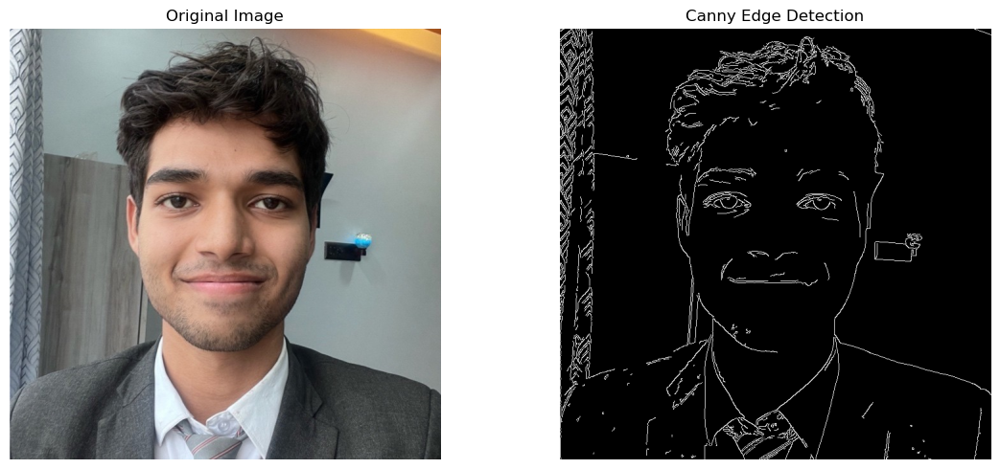

In [ ]:
plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.imshow(cv2.cvtColor(photo1, cv2.COLOR_BGR2RGB))
plt.title("Original Image")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(edges, cmap="gray")
plt.title("Canny Edge Detection")
plt.axis("off")

plt.tight_layout()
plt.show()

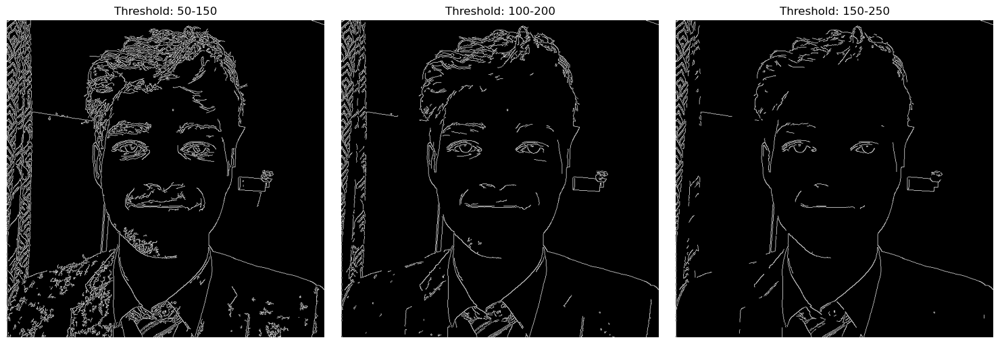

In [ ]:
# Apply Canny with different threshold values
edges_50_150 = cv2.Canny(gray_image, 50, 150)
edges_100_200 = cv2.Canny(gray_image, 100, 200)
edges_150_250 = cv2.Canny(gray_image, 150, 250)

plt.figure(figsize=(15, 5))

plt.subplot(1, 3, 1)
plt.imshow(edges_50_150, cmap="gray")
plt.title("Threshold: 50-150")
plt.axis("off")

plt.subplot(1, 3, 2)
plt.imshow(edges_100_200, cmap="gray")
plt.title("Threshold: 100-200")
plt.axis("off")

plt.subplot(1, 3, 3)
plt.imshow(edges_150_250, cmap="gray")
plt.title("Threshold: 150-250")
plt.axis("off")

plt.tight_layout()
plt.show()

In [ ]:
cv2.imwrite("outputs/canny_edges.png", edges)

print("Canny edge detection output saved successfully.")

Canny edge detection output saved successfully.


Aim: To detect edges in an image using the Canny Edge Detection algorithm.

Theory: Canny Edge Detection is an image-processing technique used to identify object boundaries. It uses noise reduction, gradient calculation, non-maximum suppression, and double thresholding to detect edges.

Conclusion: Canny Edge Detection was successfully applied to the grayscale image. Different threshold values were tested to observe their effect on edge detection.

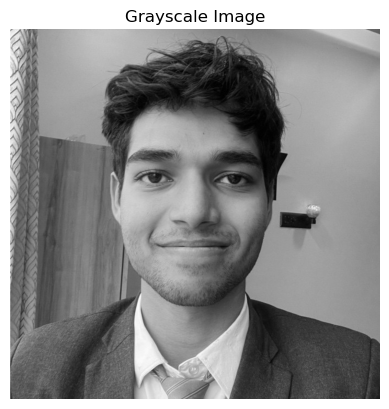

In [ ]:
# Convert original image to grayscale
gray = cv2.cvtColor(photo1, cv2.COLOR_BGR2GRAY)

plt.imshow(gray, cmap="gray")
plt.title("Grayscale Image")
plt.axis("off")
plt.show()

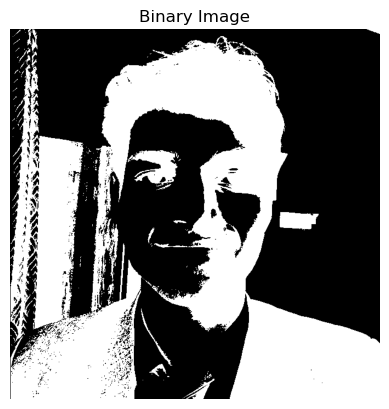

In [ ]:
# Apply Otsu's thresholding
ret, thresh = cv2.threshold(
    gray, 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU
)

# Check the image border to select the foreground polarity
border_pixels = np.concatenate([
    thresh[0, :],
    thresh[-1, :],
    thresh[:, 0],
    thresh[:, -1]
])

if np.mean(border_pixels) > 127:
    thresh = cv2.bitwise_not(thresh)

plt.imshow(thresh, cmap="gray")
plt.title("Binary Image")
plt.axis("off")
plt.show()

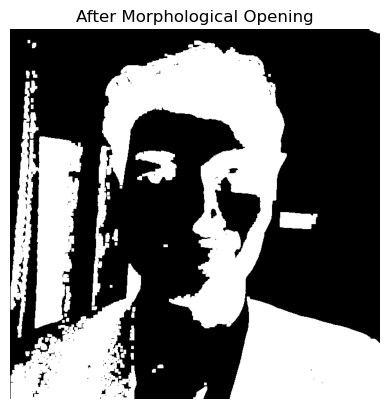

In [ ]:
# Create a 3x3 kernel
kernel = np.ones((3, 3), np.uint8)

# Apply morphological opening
opening = cv2.morphologyEx(
    thresh, cv2.MORPH_OPEN, kernel, iterations=2
)

plt.imshow(opening, cmap="gray")
plt.title("After Morphological Opening")
plt.axis("off")
plt.show()

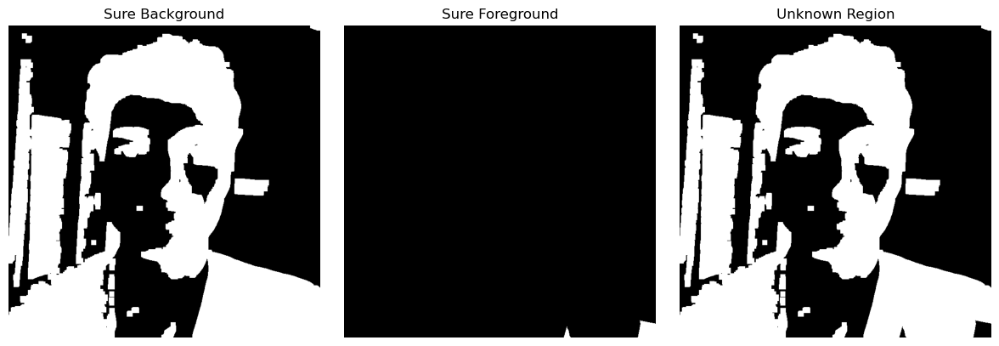

In [ ]:
# Identify sure background area
sure_bg = cv2.dilate(opening, kernel, iterations=3)

# Calculate distance transform
dist_transform = cv2.distanceTransform(
    opening, cv2.DIST_L2, 5
)

# Identify sure foreground area
ret, sure_fg = cv2.threshold(
    dist_transform,
    0.7 * dist_transform.max(),
    255,
    0
)

sure_fg = np.uint8(sure_fg)

# Identify unknown region
unknown = cv2.subtract(sure_bg, sure_fg)

plt.figure(figsize=(12, 4))

plt.subplot(1, 3, 1)
plt.imshow(sure_bg, cmap="gray")
plt.title("Sure Background")
plt.axis("off")

plt.subplot(1, 3, 2)
plt.imshow(sure_fg, cmap="gray")
plt.title("Sure Foreground")
plt.axis("off")

plt.subplot(1, 3, 3)
plt.imshow(unknown, cmap="gray")
plt.title("Unknown Region")
plt.axis("off")

plt.tight_layout()
plt.show()

In [ ]:
# Label connected foreground components
ret, markers = cv2.connectedComponents(sure_fg)

# Add one to all labels so background becomes 1 instead of 0
markers = markers + 1

# Mark unknown regions with 0
markers[unknown == 255] = 0

# Apply Watershed algorithm
watershed_image = photo1.copy()
markers = cv2.watershed(watershed_image, markers)

# Mark detected boundaries in red
watershed_image[markers == -1] = [0, 0, 255]

print("Watershed Segmentation completed successfully.")

Watershed Segmentation completed successfully.


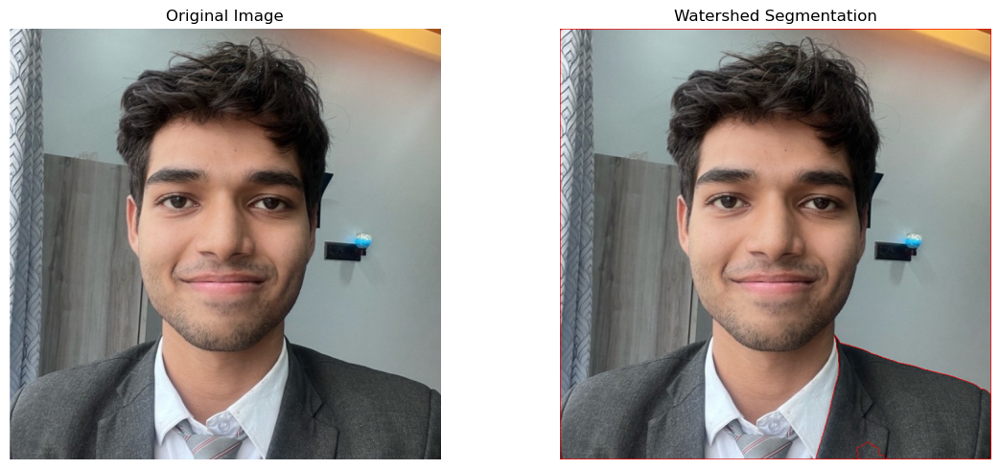

In [ ]:
plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.imshow(cv2.cvtColor(photo1, cv2.COLOR_BGR2RGB))
plt.title("Original Image")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(cv2.cvtColor(watershed_image, cv2.COLOR_BGR2RGB))
plt.title("Watershed Segmentation")
plt.axis("off")

plt.tight_layout()
plt.show()

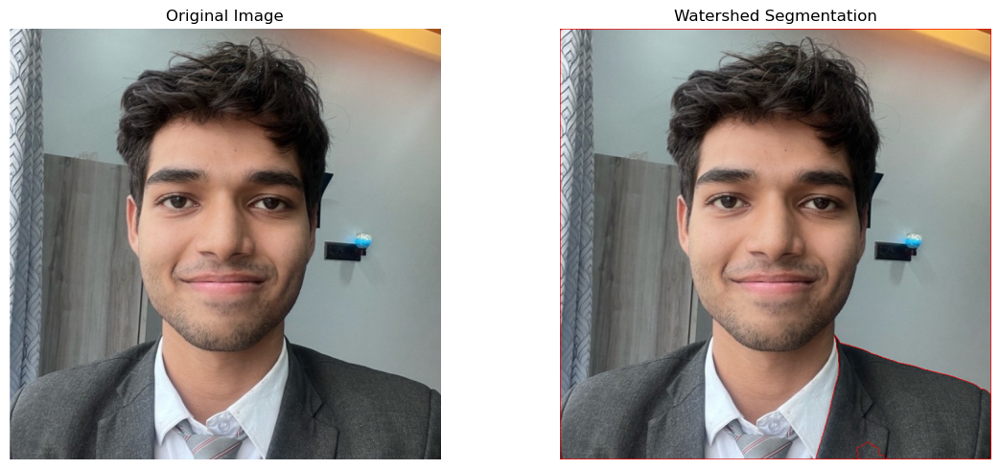

In [ ]:
plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.imshow(cv2.cvtColor(photo1, cv2.COLOR_BGR2RGB))
plt.title("Original Image")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(cv2.cvtColor(watershed_image, cv2.COLOR_BGR2RGB))
plt.title("Watershed Segmentation")
plt.axis("off")

plt.tight_layout()
plt.show()

Aim: To separate touching or overlapping objects using the Watershed Segmentation algorithm.

Theory: Watershed is an image segmentation technique that treats an image like a topographic surface. It uses foreground and background markers to identify different regions and separates objects by detecting boundaries between them.

Conclusion: Watershed segmentation was implemented using OpenCV. The algorithm identified foreground regions and marked the boundaries between segmented regions.

In [ ]:
from skimage.feature import hog

print("HOG library imported successfully.")

HOG library imported successfully.


In [ ]:
# Convert both photographs from BGR to grayscale
gray1 = cv2.cvtColor(photo1, cv2.COLOR_BGR2GRAY)
gray2 = cv2.cvtColor(photo2, cv2.COLOR_BGR2GRAY)

# Resize both images to the same dimensions
gray1 = cv2.resize(gray1, (256, 256))
gray2 = cv2.resize(gray2, (256, 256))

print("Both photographs are prepared successfully.")

Both photographs are prepared successfully.


In [ ]:
# Extract HOG features from first photograph
features1, hog_image1 = hog(
    gray1,
    orientations=9,
    pixels_per_cell=(8, 8),
    cells_per_block=(2, 2),
    visualize=True
)

print("HOG features extracted from Photo 1.")
print("Number of HOG features:", len(features1))

HOG features extracted from Photo 1.
Number of HOG features: 34596


In [ ]:
# Extract HOG features from second photograph
features2, hog_image2 = hog(
    gray2,
    orientations=9,
    pixels_per_cell=(8, 8),
    cells_per_block=(2, 2),
    visualize=True
)

print("HOG features extracted from Photo 2.")
print("Number of HOG features:", len(features2))

HOG features extracted from Photo 2.
Number of HOG features: 34596


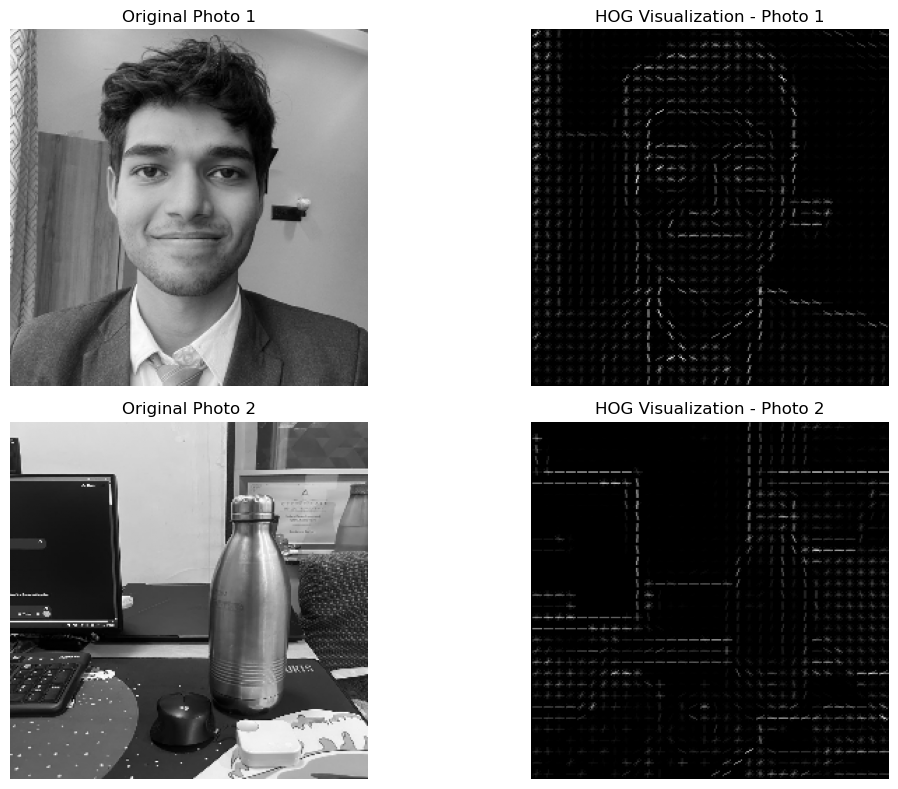

In [ ]:
plt.figure(figsize=(12, 8))

plt.subplot(2, 2, 1)
plt.imshow(gray1, cmap="gray")
plt.title("Original Photo 1")
plt.axis("off")

plt.subplot(2, 2, 2)
plt.imshow(hog_image1, cmap="gray")
plt.title("HOG Visualization - Photo 1")
plt.axis("off")

plt.subplot(2, 2, 3)
plt.imshow(gray2, cmap="gray")
plt.title("Original Photo 2")
plt.axis("off")

plt.subplot(2, 2, 4)
plt.imshow(hog_image2, cmap="gray")
plt.title("HOG Visualization - Photo 2")
plt.axis("off")

plt.tight_layout()
plt.show()

In [ ]:
# Save HOG visualization images
cv2.imwrite("outputs/hog_photo1.png", (hog_image1 * 255).astype(np.uint8))
cv2.imwrite("outputs/hog_photo2.png", (hog_image2 * 255).astype(np.uint8))

print("HOG visualization images saved successfully.")

HOG visualization images saved successfully.


### Conclusion

HOG feature extraction was successfully performed on two photographs using the Scikit-image library. The algorithm generated numerical feature descriptors and visualized image gradients, helping identify the shape and structural information of objects.

In [ ]:
# Create SIFT detector
sift = cv2.SIFT_create()

print("SIFT detector created successfully.")

SIFT detector created successfully.


In [ ]:
# Detect keypoints and descriptors in Photo 1
keypoints1, descriptors1 = sift.detectAndCompute(gray1, None)

print("Photo 1:")
print("Number of keypoints:", len(keypoints1))
print("Descriptor shape:", descriptors1.shape if descriptors1 is not None else None)

Photo 1:
Number of keypoints: 209
Descriptor shape: (209, 128)


In [ ]:
# Detect keypoints and descriptors in Photo 2
keypoints2, descriptors2 = sift.detectAndCompute(gray2, None)

print("Photo 2:")
print("Number of keypoints:", len(keypoints2))
print("Descriptor shape:", descriptors2.shape if descriptors2 is not None else None)

Photo 2:
Number of keypoints: 228
Descriptor shape: (228, 128)


In [ ]:
# Draw detected keypoints on Photo 1
sift_image1 = cv2.drawKeypoints(
    gray1,
    keypoints1,
    None,
    flags=cv2.DRAW_MATCHES_FLAGS_DRAW_RICH_KEYPOINTS
)

# Draw detected keypoints on Photo 2
sift_image2 = cv2.drawKeypoints(
    gray2,
    keypoints2,
    None,
    flags=cv2.DRAW_MATCHES_FLAGS_DRAW_RICH_KEYPOINTS
)

print("SIFT keypoints drawn successfully.")

SIFT keypoints drawn successfully.


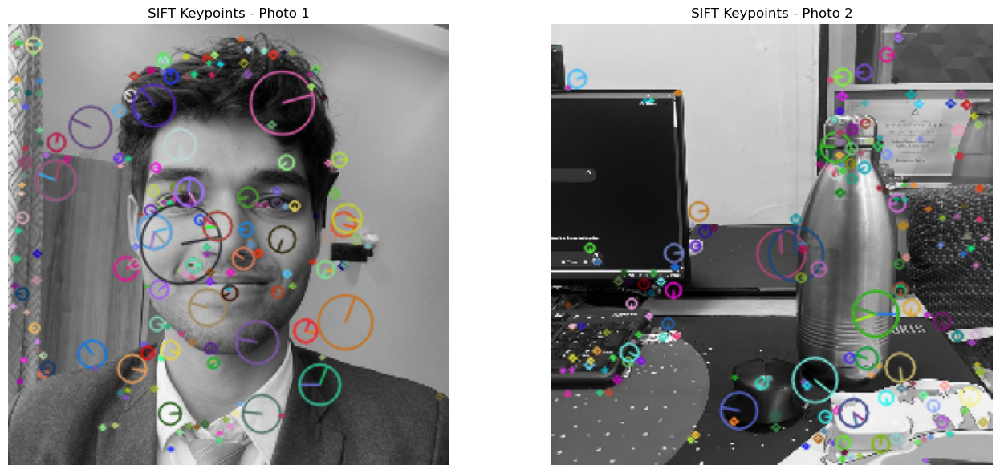

In [ ]:
plt.figure(figsize=(14, 6))

plt.subplot(1, 2, 1)
plt.imshow(sift_image1, cmap="gray")
plt.title("SIFT Keypoints - Photo 1")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(sift_image2, cmap="gray")
plt.title("SIFT Keypoints - Photo 2")
plt.axis("off")

plt.tight_layout()
plt.show()

In [ ]:
cv2.imwrite("outputs/sift_keypoints_photo1.png", sift_image1)
cv2.imwrite("outputs/sift_keypoints_photo2.png", sift_image2)

print("SIFT keypoint images saved successfully.")

SIFT keypoint images saved successfully.


### Conclusion

SIFT keypoint detection and feature descriptor extraction were successfully performed on two photographs using OpenCV. The algorithm identified distinctive points in both images and generated numerical descriptors that can be used for feature matching and object recognition.

In [ ]:
# Check whether descriptors are available
if descriptors1 is not None and descriptors2 is not None:
    print("Descriptors are available in both photographs.")
    print("Photo 1 descriptors:", descriptors1.shape)
    print("Photo 2 descriptors:", descriptors2.shape)
else:
    print("Descriptors are missing. Check your previous SIFT experiment.")

Descriptors are available in both photographs.
Photo 1 descriptors: (209, 128)
Photo 2 descriptors: (228, 128)


In [ ]:
# Create Brute Force Matcher
bf = cv2.BFMatcher(cv2.NORM_L2)

print("Brute Force Matcher created successfully.")

Brute Force Matcher created successfully.


In [ ]:
# Match descriptors using KNN
matches = bf.knnMatch(descriptors1, descriptors2, k=2)

print("Feature matching completed.")
print("Total matching pairs:", len(matches))

Feature matching completed.
Total matching pairs: 209


In [ ]:
# Apply Lowe's Ratio Test
good_matches = []

for pair in matches:
    if len(pair) == 2:
        m, n = pair

        if m.distance < 0.75 * n.distance:
            good_matches.append(m)

print("Good matches found:", len(good_matches))

Good matches found: 7


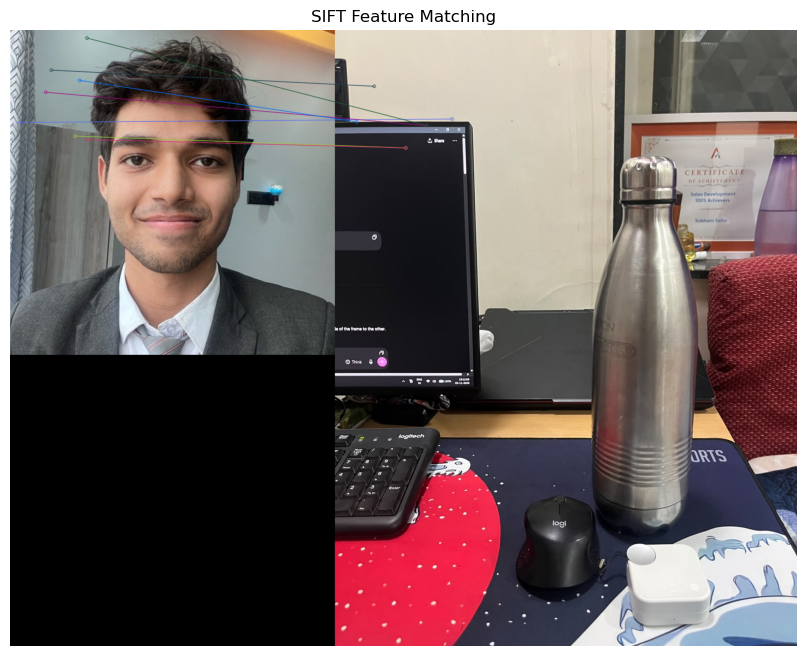

In [ ]:
# Draw good matches between both photographs
matching_result = cv2.drawMatches(
    photo1,
    keypoints1,
    photo2,
    keypoints2,
    good_matches,
    None,
    flags=cv2.DrawMatchesFlags_NOT_DRAW_SINGLE_POINTS
)

# Display the result
plt.figure(figsize=(16, 8))
plt.imshow(cv2.cvtColor(matching_result, cv2.COLOR_BGR2RGB))
plt.title("SIFT Feature Matching")
plt.axis("off")
plt.show()

In [ ]:
cv2.imwrite("outputs/sift_feature_matching.png", matching_result)

print("SIFT feature matching result saved successfully.")

SIFT feature matching result saved successfully.


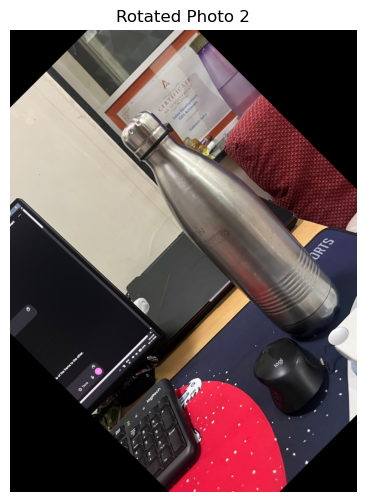

In [ ]:
# Get dimensions of Photo 2
height, width = photo2.shape[:2]

# Calculate the centre of the image
center = (width // 2, height // 2)

# Create rotation matrix for 45 degrees
rotation_matrix = cv2.getRotationMatrix2D(center, 45, 1.0)

# Rotate Photo 2
rotated_photo = cv2.warpAffine(
    photo2,
    rotation_matrix,
    (width, height)
)

# Display rotated photograph
plt.figure(figsize=(6, 6))
plt.imshow(cv2.cvtColor(rotated_photo, cv2.COLOR_BGR2RGB))
plt.title("Rotated Photo 2")
plt.axis("off")
plt.show()

In [ ]:
# Convert rotated photograph into grayscale
rotated_gray = cv2.cvtColor(rotated_photo, cv2.COLOR_BGR2GRAY)

# Extract SIFT keypoints and descriptors
rotated_keypoints, rotated_descriptors = sift.detectAndCompute(
    rotated_gray, None
)

print("Keypoints in rotated image:", len(rotated_keypoints))

if rotated_descriptors is not None:
    print("Rotated image descriptors:", rotated_descriptors.shape)

Keypoints in rotated image: 3311
Rotated image descriptors: (3311, 128)


In [ ]:
# Create a Brute Force Matcher
bf = cv2.BFMatcher(cv2.NORM_L2)

# Match descriptors using KNN
rotated_matches = bf.knnMatch(
    descriptors1,
    rotated_descriptors,
    k=2
)

# Apply Lowe's Ratio Test
good_rotated_matches = []

for pair in rotated_matches:
    if len(pair) == 2:
        m, n = pair

        if m.distance < 0.75 * n.distance:
            good_rotated_matches.append(m)

print("Good matches after rotation:", len(good_rotated_matches))

Good matches after rotation: 4


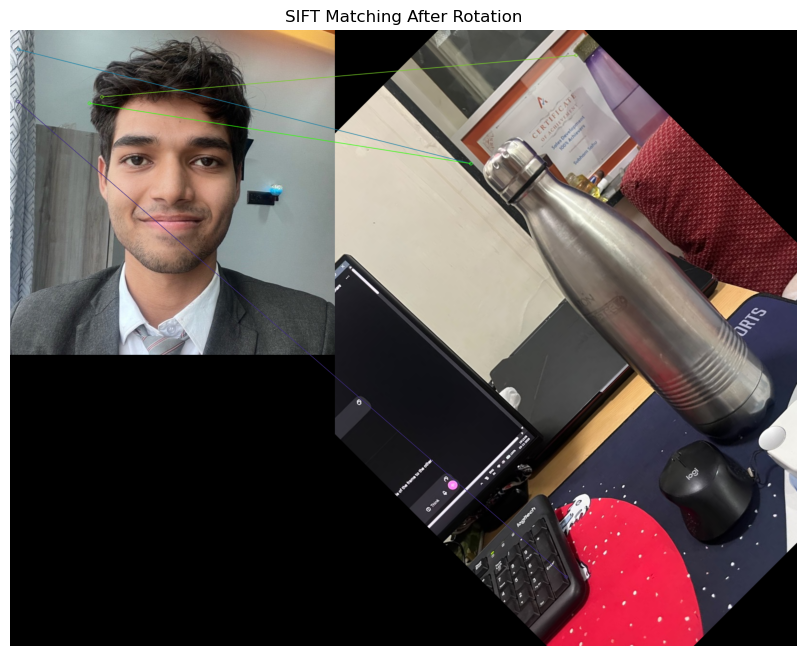

In [ ]:
# Draw matching keypoints
rotation_result = cv2.drawMatches(
    photo1,
    keypoints1,
    rotated_photo,
    rotated_keypoints,
    good_rotated_matches,
    None,
    flags=cv2.DrawMatchesFlags_NOT_DRAW_SINGLE_POINTS
)

plt.figure(figsize=(16, 8))
plt.imshow(cv2.cvtColor(rotation_result, cv2.COLOR_BGR2RGB))
plt.title("SIFT Matching After Rotation")
plt.axis("off")
plt.show()

In [ ]:
cv2.imwrite("outputs/rotated_photo2.png", rotated_photo)
cv2.imwrite("outputs/sift_rotation_matching.png", rotation_result)

print("Rotation experiment results saved successfully.")

Rotation experiment results saved successfully.


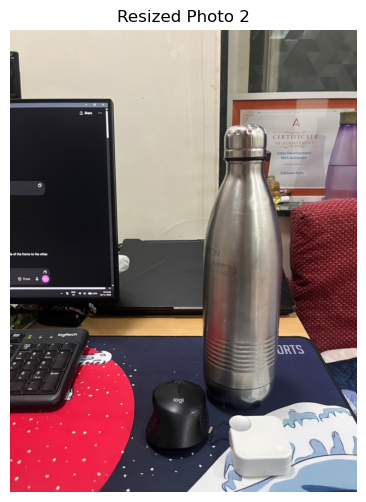

In [ ]:
# Resize Photo 2 by increasing its dimensions by 1.5 times
resized_photo = cv2.resize(
    photo2,
    None,
    fx=1.5,
    fy=1.5,
    interpolation=cv2.INTER_LINEAR
)

# Display resized photograph
plt.figure(figsize=(6, 6))
plt.imshow(cv2.cvtColor(resized_photo, cv2.COLOR_BGR2RGB))
plt.title("Resized Photo 2")
plt.axis("off")
plt.show()

In [ ]:
# Convert resized photograph into grayscale
resized_gray = cv2.cvtColor(resized_photo, cv2.COLOR_BGR2GRAY)

# Extract SIFT keypoints and descriptors
resized_keypoints, resized_descriptors = sift.detectAndCompute(
    resized_gray, None
)

print("Keypoints in resized image:", len(resized_keypoints))

if resized_descriptors is not None:
    print("Resized image descriptors:", resized_descriptors.shape)

Keypoints in resized image: 5829
Resized image descriptors: (5829, 128)


In [ ]:
# Match descriptors using KNN
resized_matches = bf.knnMatch(
    descriptors1,
    resized_descriptors,
    k=2
)

# Apply Lowe's Ratio Test
good_resized_matches = []

for pair in resized_matches:
    if len(pair) == 2:
        m, n = pair

        if m.distance < 0.75 * n.distance:
            good_resized_matches.append(m)

print("Good matches after resizing:", len(good_resized_matches))

Good matches after resizing: 3


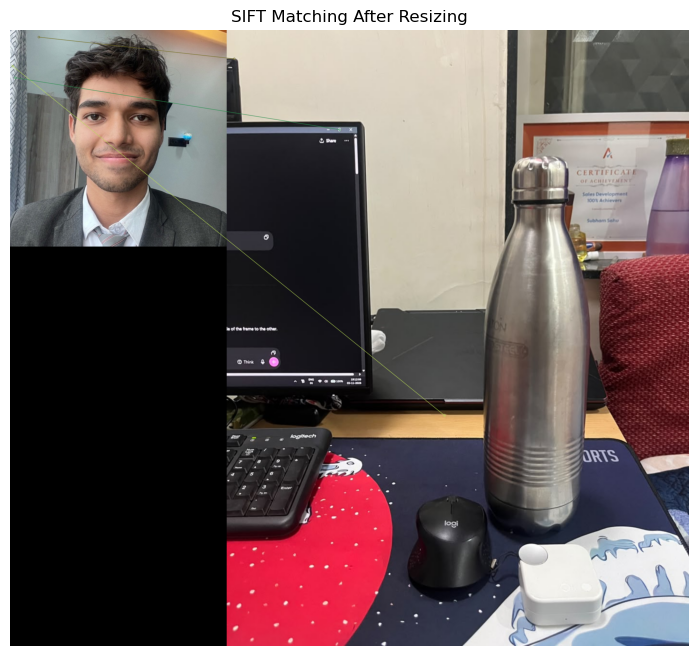

In [ ]:
# Draw matching keypoints
resize_result = cv2.drawMatches(
    photo1,
    keypoints1,
    resized_photo,
    resized_keypoints,
    good_resized_matches,
    None,
    flags=cv2.DrawMatchesFlags_NOT_DRAW_SINGLE_POINTS
)

plt.figure(figsize=(16, 8))
plt.imshow(cv2.cvtColor(resize_result, cv2.COLOR_BGR2RGB))
plt.title("SIFT Matching After Resizing")
plt.axis("off")
plt.show()

In [ ]:
cv2.imwrite("outputs/resized_photo2.png", resized_photo)
cv2.imwrite("outputs/sift_resize_matching.png", resize_result)

print("Resizing experiment results saved successfully.")

Resizing experiment results saved successfully.


In [ ]:
print("SIFT FEATURE MATCHING COMPARISON")
print("--------------------------------")

print("Original matching:", len(good_matches))
print("After rotation:", len(good_rotated_matches))
print("After resizing:", len(good_resized_matches))

SIFT FEATURE MATCHING COMPARISON
--------------------------------
Original matching: 7
After rotation: 4
After resizing: 3


In [ ]:
import cv2

print("OpenCV Version:", cv2.__version__)
print("OpenCV Location:", cv2.__file__)
print("CascadeClassifier available:", hasattr(cv2, "CascadeClassifier"))

OpenCV Version: 5.0.0
OpenCV Location: C:\ProgramData\anaconda3\Lib\site-packages\cv2\__init__.py
CascadeClassifier available: False


In [ ]:
%pip install opencv-python

  Using cached opencv_python-5.0.0.93-cp37-abi3-win_amd64.whl.metadata (20 kB)
Using cached opencv_python-5.0.0.93-cp37-abi3-win_amd64.whl (44.0 MB)
Note: you may need to restart the kernel to use updated packages.


In [ ]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

print("OpenCV Version:", cv2.__version__)
print("CascadeClassifier available:", hasattr(cv2, "CascadeClassifier"))

OpenCV Version: 5.0.0
CascadeClassifier available: False


In [ ]:
import cv2

print("OpenCV version:", cv2.__version__)
print("OpenCV location:", cv2.__file__)
print("CascadeClassifier exists:", hasattr(cv2, "CascadeClassifier"))
print("Haar cascades available:", hasattr(cv2, "data"))
print("Available Cascade functions:", [
    x for x in dir(cv2) if "Cascade" in x
])

OpenCV version: 5.0.0
OpenCV location: C:\ProgramData\anaconda3\Lib\site-packages\cv2\__init__.py
CascadeClassifier exists: False
Haar cascades available: True
Available Cascade functions: []


In [ ]:
%pip uninstall -y opencv-python opencv-contrib-python opencv-python-headless opencv-contrib-python-headless


Found existing installation: opencv-python 5.0.0.93
Uninstalling opencv-python-5.0.0.93:
  Successfully uninstalled opencv-python-5.0.0.93
Note: you may need to restart the kernel to use updated packages.


You can safely remove it manually.


In [ ]:
%pip install opencv-contrib-python==4.13.0.92

   ---------------------------------------- 0.0/46.5 MB ? eta -:--:--
   -- ------------------------------------- 3.4/46.5 MB 29.1 MB/s eta 0:00:02
   ---- ----------------------------------- 4.7/46.5 MB 12.5 MB/s eta 0:00:04
   ---- ----------------------------------- 5.5/46.5 MB 9.9 MB/s eta 0:00:05
   ---- ----------------------------------- 5.8/46.5 MB 8.3 MB/s eta 0:00:05
   ----- ---------------------------------- 6.3/46.5 MB 7.0 MB/s eta 0:00:06
   ----- ---------------------------------- 6.8/46.5 MB 5.6 MB/s eta 0:00:08
   ------ --------------------------------- 7.3/46.5 MB 5.2 MB/s eta 0:00:08
   ------- -------------------------------- 8.4/46.5 MB 5.1 MB/s eta 0:00:08
   -------- ------------------------------- 9.7/46.5 MB 5.3 MB/s eta 0:00:08
   --------- ------------------------------ 11.3/46.5 MB 5.5 MB/s eta 0:00:07
   ----------- ---------------------------- 12.8/46.5 MB 5.7 MB/s eta 0:00:06
   ----------- ---------------------------- 13.4/46.5 MB 5.5 MB/s eta 0:00:07
 

In [ ]:
import cv2

print("OpenCV Version:", cv2.__version__)
print("CascadeClassifier available:", hasattr(cv2, "CascadeClassifier"))

OpenCV Version: 4.13.0
CascadeClassifier available: True


In [ ]:
haar_cascade = cv2.CascadeClassifier(
    cv2.data.haarcascades + "haarcascade_frontalface_default.xml"
)

print("Haar Cascade loaded:", not haar_cascade.empty())

Haar Cascade loaded: True


In [ ]:
import cv2

print("OpenCV Version:", cv2.__version__)
print("CascadeClassifier available:", hasattr(cv2, "CascadeClassifier"))

haar_cascade = cv2.CascadeClassifier(
    cv2.data.haarcascades + "haarcascade_frontalface_default.xml"
)

print("Haar Cascade loaded:", not haar_cascade.empty())

OpenCV Version: 4.13.0
CascadeClassifier available: True
Haar Cascade loaded: True


In [ ]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
from ultralytics import YOLO

In [ ]:
# Load original photograph
photo1 = cv2.imread("data/photo1.jpeg")

if photo1 is None:
    print("Image not found. Check your file path.")
else:
    print("Photo loaded successfully:", photo1.shape)

Photo loaded successfully: (675, 675, 3)


In [ ]:
haar_cascade = cv2.CascadeClassifier(
    cv2.data.haarcascades + "haarcascade_frontalface_default.xml"
)

print("Haar Cascade loaded:", not haar_cascade.empty())

Haar Cascade loaded: True


In [ ]:
haar_gray = cv2.cvtColor(photo1, cv2.COLOR_BGR2GRAY)

print("Grayscale conversion completed.")

Grayscale conversion completed.


In [ ]:
faces = haar_cascade.detectMultiScale(
    haar_gray,
    scaleFactor=1.1,
    minNeighbors=5,
    minSize=(30, 30)
)

print("Number of faces detected:", len(faces))

Number of faces detected: 1


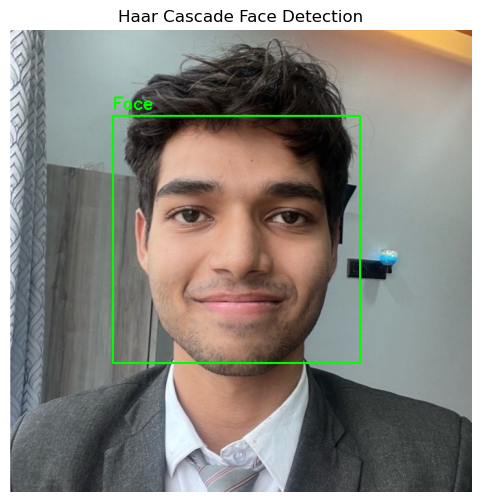

In [ ]:
haar_result = photo1.copy()

for (x, y, w, h) in faces:
    cv2.rectangle(
        haar_result,
        (x, y),
        (x + w, y + h),
        (0, 255, 0),
        2
    )

    cv2.putText(
        haar_result,
        "Face",
        (x, y - 10),
        cv2.FONT_HERSHEY_SIMPLEX,
        0.8,
        (0, 255, 0),
        2
    )

plt.figure(figsize=(8, 6))
plt.imshow(cv2.cvtColor(haar_result, cv2.COLOR_BGR2RGB))
plt.title("Haar Cascade Face Detection")
plt.axis("off")
plt.show()

In [ ]:
cv2.imwrite("outputs/haar_detection.png", haar_result)

print("Haar Cascade result saved successfully.")

Haar Cascade result saved successfully.


In [ ]:
from ultralytics import YOLO

# Load pretrained YOLOv8 Nano model
model = YOLO("yolov8n.pt")

print("YOLO model loaded successfully.")

YOLO model loaded successfully.


In [ ]:
# Perform object detection
results = model(photo1)

print("YOLO object detection completed.")


0: 640x640 1 person, 1 tie, 180.2ms
Speed: 11.1ms preprocess, 180.2ms inference, 22.2ms postprocess per image at shape (1, 3, 640, 640)
YOLO object detection completed.


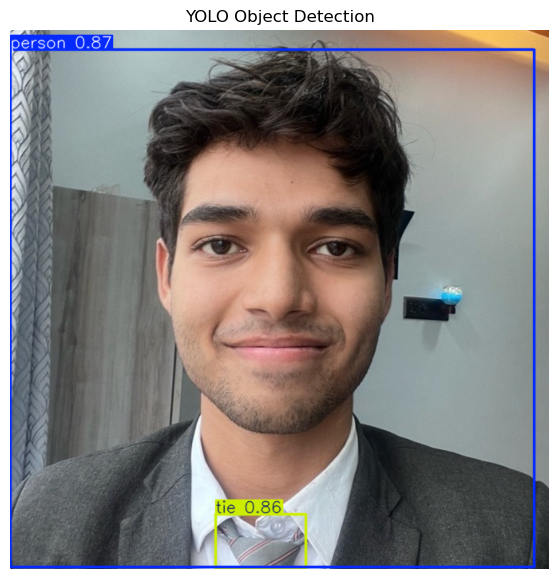

In [ ]:
# Generate image with bounding boxes and labels
yolo_result = results[0].plot()

# Display result
plt.figure(figsize=(10, 7))

plt.imshow(cv2.cvtColor(yolo_result, cv2.COLOR_BGR2RGB))
plt.title("YOLO Object Detection")
plt.axis("off")

plt.show()

In [ ]:
# Print detected objects and confidence scores
for box in results[0].boxes:

    class_id = int(box.cls[0])
    confidence = float(box.conf[0])

    class_name = model.names[class_id]

    print(
        "Object:", class_name,
        "| Confidence:", round(confidence * 100, 2), "%"
    )

Object: person | Confidence: 87.5 %
Object: tie | Confidence: 85.86 %


In [ ]:
cv2.imwrite("outputs/yolo_detection.png", yolo_result)

print("YOLO output saved successfully.")

YOLO output saved successfully.


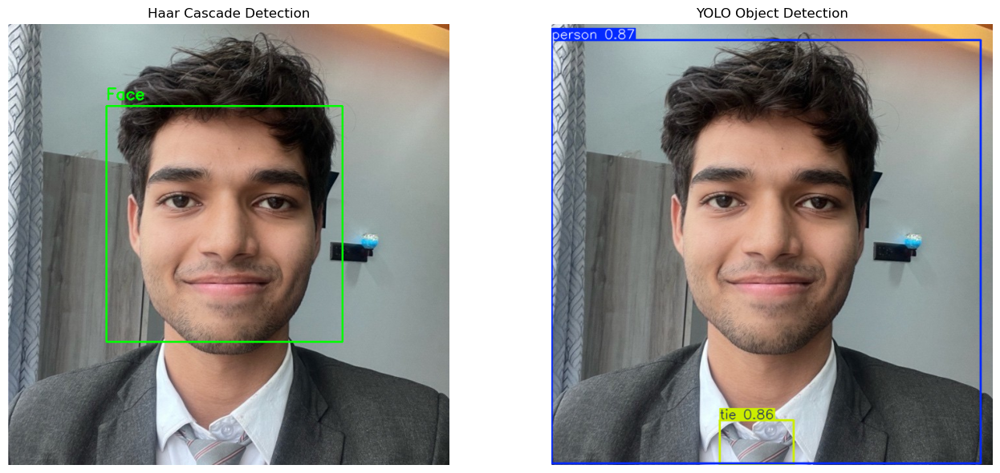

In [ ]:
plt.figure(figsize=(14, 6))

plt.subplot(1, 2, 1)
plt.imshow(cv2.cvtColor(haar_result, cv2.COLOR_BGR2RGB))
plt.title("Haar Cascade Detection")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(cv2.cvtColor(yolo_result, cv2.COLOR_BGR2RGB))
plt.title("YOLO Object Detection")
plt.axis("off")

plt.tight_layout()
plt.show()

In [ ]:
# Load the video
video_path = "data/video.mp4"

cap = cv2.VideoCapture(video_path)

if not cap.isOpened():
    print("Error: Video could not be opened.")
else:
    print("Video loaded successfully.")

    total_frames = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))
    fps = cap.get(cv2.CAP_PROP_FPS)

    print("Total Frames:", total_frames)
    print("Frames Per Second:", fps)

Video loaded successfully.
Total Frames: 701
Frames Per Second: 59.97433338086411


In [ ]:
# Read the first frame
ret, frame1 = cap.read()

# Read the second frame
ret, frame2 = cap.read()

if frame1 is not None and frame2 is not None:
    print("Two consecutive frames extracted successfully.")
else:
    print("Unable to extract frames.")

Two consecutive frames extracted successfully.


In [ ]:
# Convert both frames into grayscale
gray1 = cv2.cvtColor(frame1, cv2.COLOR_BGR2GRAY)
gray2 = cv2.cvtColor(frame2, cv2.COLOR_BGR2GRAY)

# Apply Gaussian Blur to reduce noise
gray1 = cv2.GaussianBlur(gray1, (5, 5), 0)
gray2 = cv2.GaussianBlur(gray2, (5, 5), 0)

print("Frames converted to grayscale successfully.")

Frames converted to grayscale successfully.


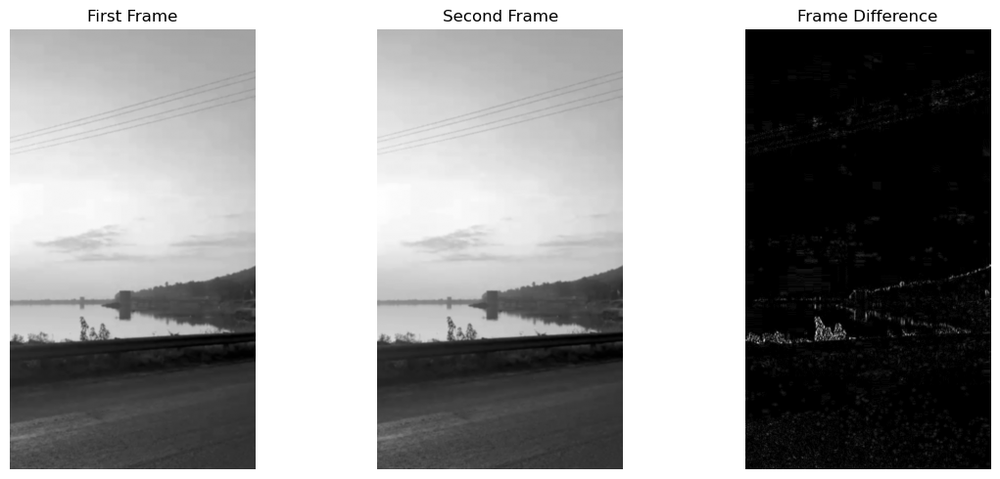

In [ ]:
# Calculate absolute difference between frames
frame_difference = cv2.absdiff(gray1, gray2)

plt.figure(figsize=(12, 5))

plt.subplot(1, 3, 1)
plt.imshow(gray1, cmap="gray")
plt.title("First Frame")
plt.axis("off")

plt.subplot(1, 3, 2)
plt.imshow(gray2, cmap="gray")
plt.title("Second Frame")
plt.axis("off")

plt.subplot(1, 3, 3)
plt.imshow(frame_difference, cmap="gray")
plt.title("Frame Difference")
plt.axis("off")

plt.tight_layout()
plt.show()

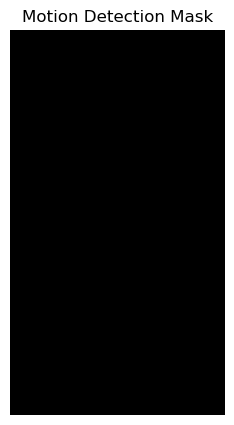

In [ ]:
# Apply thresholding to the difference image
threshold_value = 25

ret, motion_mask = cv2.threshold(
    frame_difference,
    threshold_value,
    255,
    cv2.THRESH_BINARY
)

plt.figure(figsize=(7, 5))
plt.imshow(motion_mask, cmap="gray")
plt.title("Motion Detection Mask")
plt.axis("off")
plt.show()

In [ ]:
# Find contours in the motion mask
contours, hierarchy = cv2.findContours(
    motion_mask,
    cv2.RETR_EXTERNAL,
    cv2.CHAIN_APPROX_SIMPLE
)

# Copy the second frame
motion_result = frame2.copy()

# Draw bounding boxes around significant motion regions
for contour in contours:

    if cv2.contourArea(contour) > 500:

        x, y, w, h = cv2.boundingRect(contour)

        cv2.rectangle(
            motion_result,
            (x, y),
            (x + w, y + h),
            (0, 255, 0),
            2
        )

print("Motion regions identified.")

Motion regions identified.


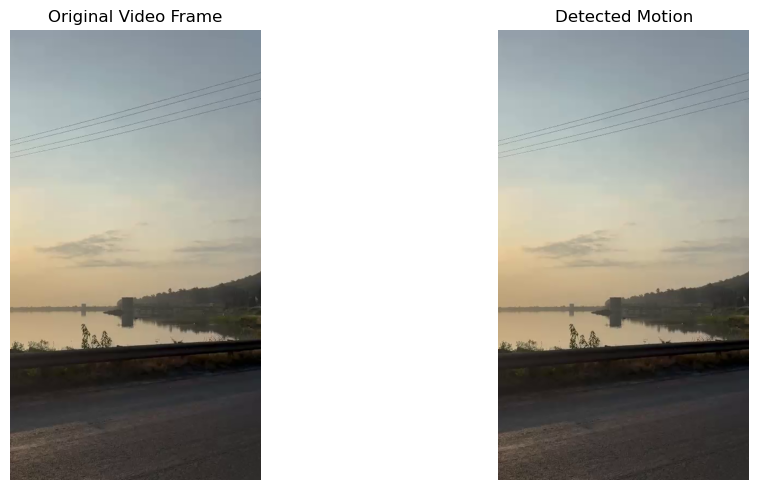

In [ ]:
plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.imshow(cv2.cvtColor(frame2, cv2.COLOR_BGR2RGB))
plt.title("Original Video Frame")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(cv2.cvtColor(motion_result, cv2.COLOR_BGR2RGB))
plt.title("Detected Motion")
plt.axis("off")

plt.tight_layout()
plt.show()

In [ ]:
cv2.imwrite("outputs/frame_difference.png", frame_difference)
cv2.imwrite("outputs/motion_mask.png", motion_mask)
cv2.imwrite("outputs/motion_detection.png", motion_result)

print("Frame Differencing results saved successfully.")

Frame Differencing results saved successfully.


In [ ]:
cap.release()

print("Video released successfully.")

Video released successfully.


In [ ]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
import os

video_path = "data/video.mp4"

cap = cv2.VideoCapture(video_path)

if not cap.isOpened():
    raise FileNotFoundError("Unable to open video: " + video_path)

print("Video loaded successfully.")

print("Total frames:", int(cap.get(cv2.CAP_PROP_FRAME_COUNT)))
print("FPS:", cap.get(cv2.CAP_PROP_FPS))

Video loaded successfully.
Total frames: 701
FPS: 59.97433338086411


In [ ]:
# Create Gaussian Mixture Model background subtractor

background_subtractor = cv2.createBackgroundSubtractorMOG2(
    history=500,
    varThreshold=16,
    detectShadows=True
)

print("GMM Background Subtractor created successfully.")

GMM Background Subtractor created successfully.


In [ ]:
# Store selected frames and foreground masks
gmm_frames = []
gmm_masks = []

frame_count = 0

while True:

    ret, frame = cap.read()

    if not ret:
        break

    # Apply GMM background subtraction
    foreground_mask = background_subtractor.apply(frame)

    frame_count += 1

    # Save a sample every 30 frames
    if frame_count % 30 == 0:
        gmm_frames.append(frame.copy())
        gmm_masks.append(foreground_mask.copy())

cap.release()

print("GMM processing completed.")
print("Total frames processed:", frame_count)
print("Sample frames collected:", len(gmm_frames))

GMM processing completed.
Total frames processed: 701
Sample frames collected: 23


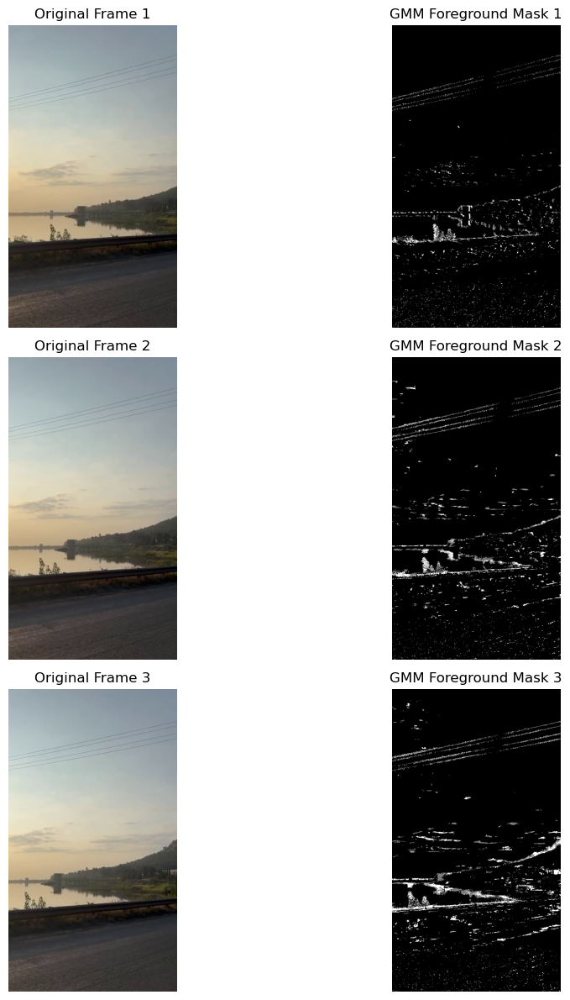

In [ ]:
# Display sample frames and their foreground masks

if len(gmm_frames) == 0:
    print("No sample frames available. Check the video length.")
else:
    num_samples = min(3, len(gmm_frames))

    plt.figure(figsize=(12, num_samples * 4))

    for i in range(num_samples):

        plt.subplot(num_samples, 2, 2 * i + 1)
        plt.imshow(cv2.cvtColor(gmm_frames[i], cv2.COLOR_BGR2RGB))
        plt.title(f"Original Frame {i + 1}")
        plt.axis("off")

        plt.subplot(num_samples, 2, 2 * i + 2)
        plt.imshow(gmm_masks[i], cmap="gray", vmin=0, vmax=255)
        plt.title(f"GMM Foreground Mask {i + 1}")
        plt.axis("off")

    plt.tight_layout()
    plt.show()

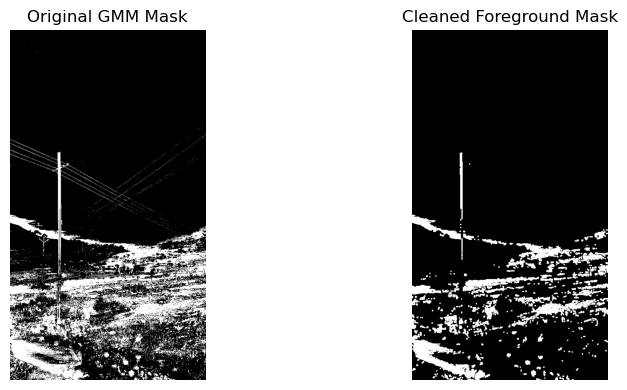

In [ ]:
# Select the last sampled foreground mask

if len(gmm_masks) > 0:

    selected_frame = gmm_frames[-1]
    selected_mask = gmm_masks[-1]

    # Keep foreground pixels, excluding shadow pixels
    _, clean_mask = cv2.threshold(
        selected_mask,
        200,
        255,
        cv2.THRESH_BINARY
    )

    # Create kernel
    kernel = np.ones((3, 3), np.uint8)

    # Remove small white noise
    clean_mask = cv2.morphologyEx(
        clean_mask,
        cv2.MORPH_OPEN,
        kernel
    )

    plt.figure(figsize=(10, 4))

    plt.subplot(1, 2, 1)
    plt.imshow(selected_mask, cmap="gray")
    plt.title("Original GMM Mask")
    plt.axis("off")

    plt.subplot(1, 2, 2)
    plt.imshow(clean_mask, cmap="gray")
    plt.title("Cleaned Foreground Mask")
    plt.axis("off")

    plt.tight_layout()
    plt.show()

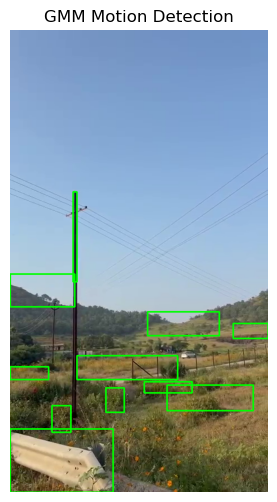

In [ ]:
if len(gmm_masks) > 0:

    contours, _ = cv2.findContours(
        clean_mask,
        cv2.RETR_EXTERNAL,
        cv2.CHAIN_APPROX_SIMPLE
    )

    gmm_result = selected_frame.copy()

    for contour in contours:

        if cv2.contourArea(contour) > 500:

            x, y, w, h = cv2.boundingRect(contour)

            cv2.rectangle(
                gmm_result,
                (x, y),
                (x + w, y + h),
                (0, 255, 0),
                2
            )

    plt.figure(figsize=(10, 6))
    plt.imshow(cv2.cvtColor(gmm_result, cv2.COLOR_BGR2RGB))
    plt.title("GMM Motion Detection")
    plt.axis("off")
    plt.show()

In [ ]:
os.makedirs("outputs", exist_ok=True)

if len(gmm_masks) > 0:

    cv2.imwrite("outputs/gmm_foreground_mask.png", selected_mask)

    cv2.imwrite("outputs/gmm_clean_mask.png", clean_mask)

    cv2.imwrite("outputs/gmm_motion_detection.png", gmm_result)

    print("GMM output images saved successfully.")

GMM output images saved successfully.


### Conclusion

Gaussian Mixture Model (GMM) Background Subtraction was implemented using OpenCV's MOG2 algorithm.

The algorithm processed consecutive video frames and generated foreground masks to identify moving objects.

Thresholding and morphological opening were applied to reduce shadows and small noise regions. Bounding boxes were used to highlight significant foreground regions.

Unlike frame differencing, GMM uses a learned background model to distinguish moving foreground objects from the background.

In [ ]:
# Load video
video_path = "data/video.mp4"

cap = cv2.VideoCapture(video_path)

if not cap.isOpened():
    raise FileNotFoundError("Unable to open video.")

ret, old_frame = cap.read()

if not ret:
    raise ValueError("Unable to read the first video frame.")

old_gray = cv2.cvtColor(old_frame, cv2.COLOR_BGR2GRAY)

print("Video loaded successfully.")

Video loaded successfully.


In [ ]:
# Detect good feature points
feature_params = dict(
    maxCorners=100,
    qualityLevel=0.3,
    minDistance=7,
    blockSize=7
)

p0 = cv2.goodFeaturesToTrack(
    old_gray,
    mask=None,
    **feature_params
)

if p0 is None:
    raise ValueError("No trackable feature points found in the first frame.")

print("Feature points detected:", len(p0))

Feature points detected: 29


In [ ]:
# Define Lucas-Kanade Optical Flow parameters
lk_params = dict(
    winSize=(15, 15),
    maxLevel=2,
    criteria=(
        cv2.TERM_CRITERIA_EPS | cv2.TERM_CRITERIA_COUNT,
        10,
        0.03
    )
)

print("Lucas-Kanade parameters configured.")

Lucas-Kanade parameters configured.


In [ ]:
# Read the next frame
ret, frame = cap.read()

if not ret:
    raise ValueError("Unable to read the next video frame.")

frame_gray = cv2.cvtColor(frame, cv2.COLOR_BGR2GRAY)

# Calculate optical flow
p1, status, error = cv2.calcOpticalFlowPyrLK(
    old_gray,
    frame_gray,
    p0,
    None,
    **lk_params
)

print("Optical flow calculated successfully.")

Optical flow calculated successfully.


In [ ]:
# Select successfully tracked points
good_new = p1[status == 1]
good_old = p0[status == 1]

print("Successfully tracked points:", len(good_new))

Successfully tracked points: 29


In [ ]:
# Create a blank mask for drawing motion trails
mask = np.zeros_like(frame)

# Draw motion vectors
for new, old in zip(good_new, good_old):

    a, b = new.ravel()
    c, d = old.ravel()

    # Draw line showing movement
    cv2.line(
        mask,
        (int(a), int(b)),
        (int(c), int(d)),
        (0, 255, 0),
        2
    )

    # Draw circle at the new point
    cv2.circle(
        frame,
        (int(a), int(b)),
        4,
        (0, 0, 255),
        -1
    )

# Combine frame and motion vectors
optical_flow_result = cv2.add(frame, mask)

print("Motion vectors drawn successfully.")

Motion vectors drawn successfully.


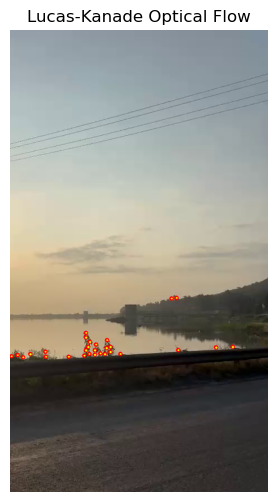

In [ ]:
plt.figure(figsize=(12, 6))

plt.imshow(
    cv2.cvtColor(optical_flow_result, cv2.COLOR_BGR2RGB)
)

plt.title("Lucas-Kanade Optical Flow")
plt.axis("off")

plt.show()

In [ ]:
os.makedirs("outputs", exist_ok=True)

cv2.imwrite(
    "outputs/lucas_kanade_optical_flow.png",
    optical_flow_result
)

print("Optical Flow output saved successfully.")

Optical Flow output saved successfully.


In [ ]:
cap.release()

print("Video released successfully.")

Video released successfully.


### Conclusion

Lucas–Kanade Optical Flow was successfully implemented using OpenCV. Feature points were detected in the first video frame and tracked in the subsequent frame.

The movement of successfully tracked points was visualized using lines and circles. This technique helps estimate the direction and displacement of moving objects between consecutive video frames.

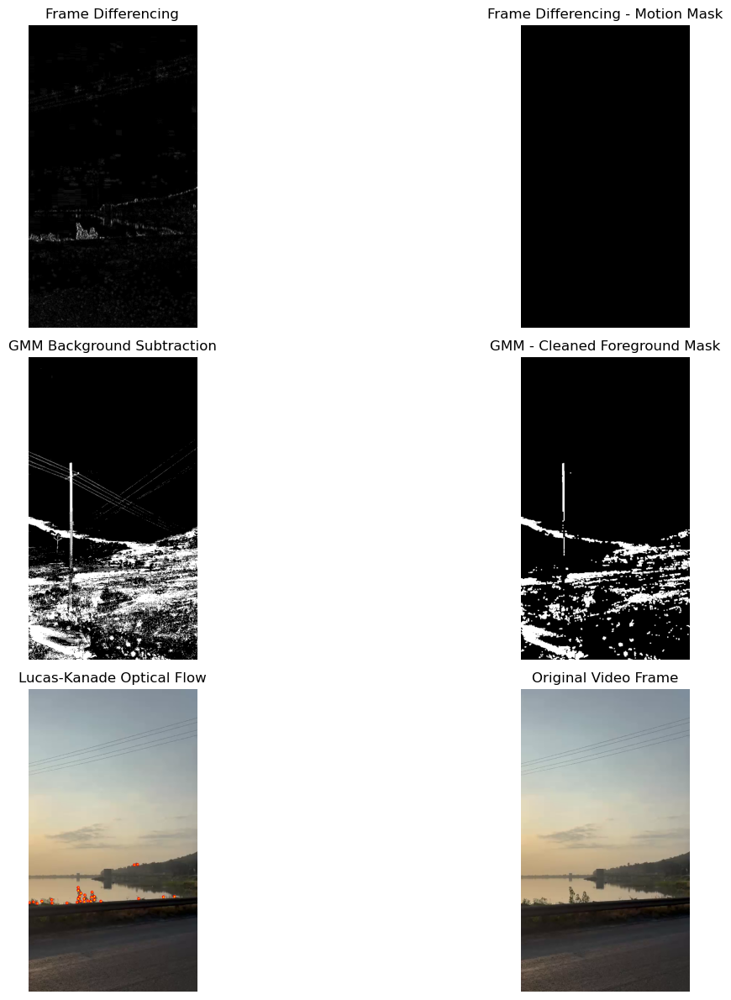

In [ ]:
plt.figure(figsize=(16, 12))

# Frame Differencing
plt.subplot(3, 2, 1)
plt.imshow(frame_difference, cmap="gray")
plt.title("Frame Differencing")
plt.axis("off")

plt.subplot(3, 2, 2)
plt.imshow(motion_mask, cmap="gray")
plt.title("Frame Differencing - Motion Mask")
plt.axis("off")

# GMM Background Subtraction
plt.subplot(3, 2, 3)
plt.imshow(selected_mask, cmap="gray")
plt.title("GMM Background Subtraction")
plt.axis("off")

plt.subplot(3, 2, 4)
plt.imshow(clean_mask, cmap="gray")
plt.title("GMM - Cleaned Foreground Mask")
plt.axis("off")

# Lucas-Kanade Optical Flow
plt.subplot(3, 2, 5)
plt.imshow(cv2.cvtColor(
    optical_flow_result, cv2.COLOR_BGR2RGB
))
plt.title("Lucas-Kanade Optical Flow")
plt.axis("off")

plt.subplot(3, 2, 6)
plt.imshow(cv2.cvtColor(
    frame2, cv2.COLOR_BGR2RGB
))
plt.title("Original Video Frame")
plt.axis("off")

plt.tight_layout()
plt.show()

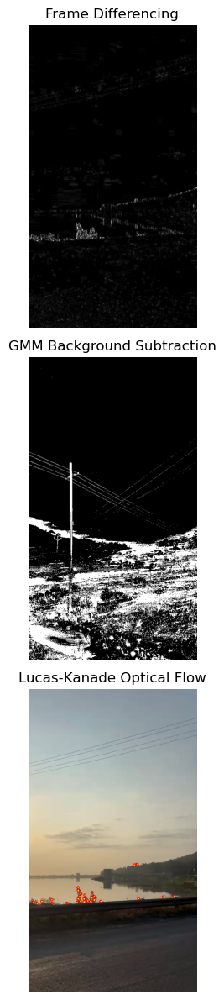

Combined comparison saved successfully.


In [ ]:
os.makedirs("outputs", exist_ok=True)

plt.figure(figsize=(16, 12))

plt.subplot(3, 1, 1)
plt.imshow(frame_difference, cmap="gray")
plt.title("Frame Differencing")
plt.axis("off")

plt.subplot(3, 1, 2)
plt.imshow(selected_mask, cmap="gray")
plt.title("GMM Background Subtraction")
plt.axis("off")

plt.subplot(3, 1, 3)
plt.imshow(cv2.cvtColor(
    optical_flow_result, cv2.COLOR_BGR2RGB
))
plt.title("Lucas-Kanade Optical Flow")
plt.axis("off")

plt.tight_layout()
plt.savefig("outputs/motion_techniques_comparison.png")
plt.show()

print("Combined comparison saved successfully.")

## Comparison of Motion Estimation Techniques

| Feature | Frame Differencing | GMM Background Subtraction | Lucas-Kanade Optical Flow |
|---|---|---|---|
| Working principle | Compares consecutive frames | Learns the background using Gaussian models | Tracks feature points |
| Motion detection | Detects pixel changes | Separates foreground from background | Estimates point displacement |
| Output | Binary motion mask | Foreground mask | Motion vectors |
| Background learning | No | Yes | No |
| Noise sensitivity | Can be sensitive to noise | Depends on background model | Depends on feature quality |
| Main application | Basic motion detection | Surveillance and foreground detection | Object tracking and movement estimation |

### Conclusion

Three motion estimation techniques were implemented and compared using OpenCV.

Frame Differencing identified changes between consecutive frames. GMM Background Subtraction separated foreground objects from the learned background. Lucas–Kanade Optical Flow tracked feature points and visualized their movement using motion vectors.

Each technique provides a different approach to motion analysis and is useful for different computer vision applications.